In [2]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# cargar archivos
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')

In [4]:
# mostrar las primeras 5 filas de traffic'
traffic.head(5)

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [5]:
# mostrar las primeras 5 filas de eco
eco.head(5)

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


In [6]:
# Examinar la estructura de traffic
traffic.info()
traffic.head(3)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232


In [7]:
# Examinar la estructura de eco
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"


In [8]:
# Estandarizar los nombres de las columnas de traffic
traffic = traffic.rename(columns={"Country":"country","UpdateTimeUTC":"update_time_utc", "City":"city", "JamsDelay":"jams_delay", "TrafficIndexLive":"traffic_index_live", "UpdateTimeUTCWeekAgo":"update_time_utc_week_ago"})

# verificar cambios
traffic.columns

Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'JamsLengthInKms', 'JamsCount',
       'TrafficIndexWeekAgo', 'update_time_utc_week_ago',
       'TravelTimeLivePer10KmsMins', 'TravelTimeHistoricPer10KmsMins',
       'MinsDelay'],
      dtype='object')

In [9]:
# Estandarizar los nombres de las columnas de eco
eco = eco.rename(columns={"Year":"year","Country":"country","City":"city", "City GDP/capita":"city_gdp_capita" , 'Unemployment %':'unemployment_pct','PM2.5 (μg/m³)':'pm2.5','Population (M)':'population_m'})


# verificar cambios
eco.columns

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm2.5', 'population_m'],
      dtype='object')

In [10]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors='coerce')
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'], errors='coerce')

# verificar el cambio
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype         
---  ------                          --------------    -----         
 0   country                         1004464 non-null  object        
 1   city                            1004464 non-null  object        
 2   update_time_utc                 1004464 non-null  datetime64[ns]
 3   jams_delay                      1004464 non-null  float64       
 4   traffic_index_live              1004464 non-null  float64       
 5   JamsLengthInKms                 1004464 non-null  float64       
 6   JamsCount                       1004464 non-null  float64       
 7   TrafficIndexWeekAgo             1004464 non-null  float64       
 8   update_time_utc_week_ago        1004464 non-null  datetime64[ns]
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64       
 10  TravelTimeHistoricPer10KmsMins  1004464 no

In [11]:
# Limpia separadores y convierte columnas numéricas en eco
eco['city_gdp_capita'] = eco['city_gdp_capita'].astype(str).str.replace('.', '').str.replace(',', '.').astype(float)
eco['unemployment_pct'] = eco['unemployment_pct'].str.replace('%', '').str.replace(',', '.').astype(float)
eco['population_m'] = eco['population_m'].str.replace(',','.').astype(float)

# Calcula la población total en unidades absolutas (Multiplica * 1000000)
eco['population'] = (eco['population_m'] * 1000000)

# verificar el cambio
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm2.5             30 non-null     object 
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(4), int64(1), object(3)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm2.5,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13.6,13600000.0


In [12]:
# Extraer el año de las fechas en update_time_utc
traffic['year'] = traffic['update_time_utc'].dt.year

# Verificar cambio
traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,update_time_utc_week_ago,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [13]:
# Filtra los registros del año 2024
traffic_2024 = traffic[traffic['year']==2024].copy()

eco_2024 = eco[eco['year']==2024].copy()

# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())


,country,city,update_time_utc,jams_delay,traffic_index_live,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,update_time_utc_week_ago,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm2.5,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000.0


In [14]:
# Calcular los  promedios de trafico por ciudad, país y año
traffic_2024 = traffic.rename(columns={
    'JamsLengthInKms': 'jams_length_kms',
    'JamsCount': 'jams_count',
    'TrafficIndexWeekAgo': 'traffic_index_week_ago',
    'TravelTimeLivePer10KmsMins': 'travel_time_live_per_10kms_mins',
    'MinsDelay': 'mins_delay',
    'TravelTimeHistoricPer10KmsMins': 'travel_time_hist_per_10kms_mins'})

metricas = [
    'jams_delay', 
    'traffic_index_live', 
    'jams_length_kms', 
    'jams_count', 
    'mins_delay', 
    'travel_time_live_per_10kms_mins', 
    'travel_time_hist_per_10kms_mins']


traffic_city_year_2024 =  (traffic_2024.groupby(["city","country" ,"year"])[metricas].agg('mean').reset_index())

# Mostrar resultado
traffic_city_year_2024.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,a-coruna,ESP,2025,11.323684,11.055921,1.161513,3.105263,0.402193,15.839864,15.437671
2,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
3,aachen,DEU,2025,16.278289,18.269737,3.400000,4.144737,0.648249,13.347184,12.698935
4,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016


In [15]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)


,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
442,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
704,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
492,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
400,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
422,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
25,almere,NLD,2025,1.833667,5.040000,0.214333,0.596667,-0.063112,9.455774,9.518886
223,dunedin,NZL,2025,1.644408,11.023026,0.306250,0.526316,0.101581,15.436593,15.335011
291,hamilton,NZL,2025,1.448658,7.892617,0.161745,0.473154,-0.197995,13.097767,13.295761
234,el-paso,USA,2024,0.299024,2.340435,0.031114,0.078118,-0.250676,10.690269,10.940945


La ciudad con el mayor tiempo promedio de tráfico es Ciudad de México, con un tiempo promedio de 2833.06 minutos de retraso en tráfico.

In [16]:
# Seleccionar columnas clave de tráfico y economía
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_kms','jams_count','mins_delay',
             'travel_time_live_per_10kms_mins','travel_time_hist_per_10kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm2.5','population']

# Usar .copy() para crear los dos nuevos datasets reducidos
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Unir datasets
merged = pd.merge(traffic_2024_small, eco_2024_small, on=['city','year'],how='inner')

# Mostrar las primeras 5 filas
merged.head(5)

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,city_gdp_capita,unemployment_pct,pm2.5,population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,"16,80",6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,"17,60",11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,"12,80",4800000.0
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,"14,50",15400000.0
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,"13,50",3700000.0


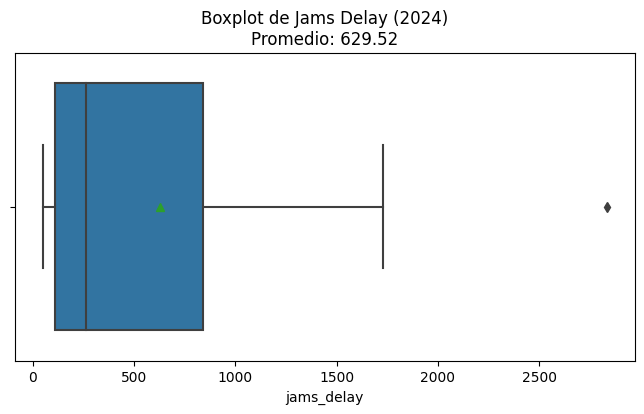

In [17]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay
plt.figure(figsize=(8, 4))
sns.boxplot(data=merged, x='jams_delay', showmeans=True)

# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de Jams Delay (2024)\nPromedio: {mean_value:.2f}')
plt.show()


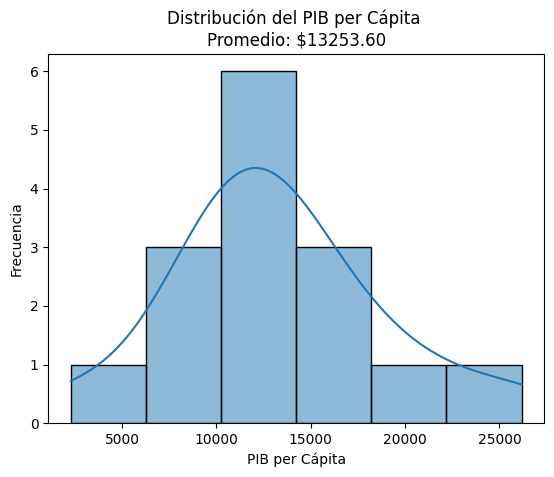

In [18]:

# Crear histograma para ver la distribución de la economía (city_gdp_capita)
promedio_pib = merged['city_gdp_capita'].mean()
sns.histplot(data=merged, x='city_gdp_capita', kde=True)

plt.title(f'Distribución del PIB per Cápita \nPromedio: ${promedio_pib:.2f}')
plt.xlabel('PIB per Cápita')
plt.ylabel('Frecuencia')

plt.show()





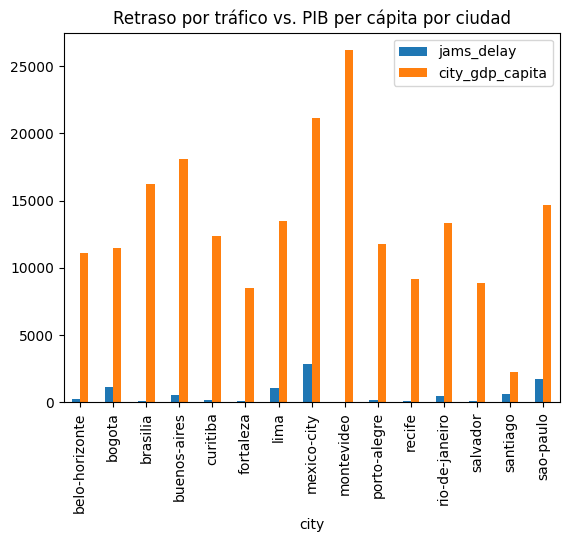

In [19]:
# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
merged.plot(x='city', kind='bar', y=['jams_delay', 'city_gdp_capita'])

plt.xticks(rotation=90)
plt.title('Retraso por tráfico vs. PIB per cápita por ciudad')
plt.show()


    Según el análisis y las gráficas realizadas , no existe una relación clara y evidente entre el PIB per cápita y el nivel de congestión en las ciudades. En nuestra gráfica de "Retraso por tráfico vs. PIB per cápita por ciudad", podemos observar que no hay un patrón que nos permita establecer una correlación entre ambas, observando casos como el de Montevideo, que presenta el PIB más alto entre las analizadas y un valor retraso en tráfico cercano al 0 y casos como el de Ciudad de México, en donde teniendo un PIB alto, se puede observar un nivel mucho mayor de congestión. También se pueden observar casos como el de Santiago, que teniendo el PIB menor de entre las ciudades analizadas, presenta un nivel de congestión considerable respecto a su PIB. 
    Es por ello que se concluye que el PIB per cápita no es un determinante directo de los niveles de congestión, sino que deben analizarse muchos otros factores influyentes en este, como podrían serlo la densidad poblacional, infraestructura vial y calidad del transporte público, entre otros.

In [20]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)


---

# 🧾 Resumen ejecutivo

Según los resultados del análisis y las gráficas realizadas, se puede evidenciar que no existe una correlación clara ni directa entre la movilidad urbana (comprendida en este caso bajo la variable de Jams Delay) y el PIB per cápita, observando casos en donde se presenta un mayor PIB y un menor Retraso en tráfico y otros en donde se presenta un menor PIB y un mayor retraso en tráfico. Se hace necesario evaluar otras variables incidentes en el tráfico, como la infraestructura vial y calidad del transporte público, entre otros.
Se utilizaron para este análisis variables para analizar el tráfico como demora en tráfico, longitud de tráfico, tiempo por cada 10 kilómetros, entre otros, así como variables económicas como tasa de desempleo, ingreso per cápita por ciudad, población, pm.25, entre otros. Así mismo, los países que hicieron parte de este análisis fueron Argentina, Brasil, Chile, Colombia, México, Perú, Uruguay, incluyendo 15 de sus ciudades, en los años 2023, 2024 y 2025.

En la etapa inicial del análisis, se hizo una primera observación de la estructura y contenido de ambos datasets, para seguidamente pasar a realizar limpieza y preparación, corrección de datos/formatos inconsistentes y extracción de datos relevates. Una vez los datos se encontraron debidamente preparados, se procedió a agrupar por ciudad-año, hacer cálculos y unir ambas bases de datos con INNER merge para poder hacer un mejor análisis a través de la realización de gráficos de barras, histograma y boxplot. En ellos se podía evidenciar las distribuciones del PIB per cápita así como su forma y promedio y detectar valores atípicos; no obstante, se hace necesario analizar la presencia de outliers que se observaron en el Boxplot de Jams delay.

El caso que convendría más analizar, sería el de Montevideo, donde se encuentra el mayor PIB per cápita, al tiempo que el menor tiempo de retraso en tráfico. Al realizar análisis adicionales que pudieran evidenciar otras variables que puedan estar relacionadas e influyendo paralelamente en estas, se podría determinar en qué se hace necesario invertir o mejorar por ciudad. Otro caso que convendría analizar, sería el de Santiago, pues el análisis que muestra una mayor proporcionalidad entre la demora en tráfico y PIB per cápita.
